# Food Delivery Time Prediction: Regression & Classification Analysis

## 1. Project Overview

### Context & Problem Statement
In food delivery operations, estimating delivery duration and anticipating delivery delays are critical for managing customer expectations, driver dispatch, and kitchen fulfillment. 

This project explores an end-to-end machine learning workflow using tabular order metadata from a food delivery service. The investigation tackles two complementary prediction tasks:
1. **Continuous Regression**: Predicting exact `Delivery_Time` (in minutes) from operational and environmental features using Ordinary Least Squares (OLS) Linear Regression.
2. **Binary Classification**: Categorizing deliveries into relative performance tiers (**Fast** vs. **Delayed**) based on the dataset median delivery duration using Logistic Regression.

### Operational Definition of "Delayed"
> **Important Note on Labels**: Within this dataset, "Delayed" is defined strictly relative to the internal median delivery time ($72.78$ minutes), representing orders that fall in the slower 50% of completed deliveries. This label does **not** indicate a missed promised customer SLA or late dispatch contract.

### Project Pipeline
- **Data Loading & Inspection**: Verifying schemas, formats, and structural integrity.
- **Data Cleaning & Preprocessing**: Handling duplicates, missing values, and dropping non-predictive identifiers/raw coordinates.
- **Exploratory Data Analysis (EDA)**: Investigating distributions, correlation structures, and feature relationships with delivery duration.
- **Feature Engineering**: Establishing explicit ordinal hierarchies (`Traffic_Conditions`, `Order_Priority`) and dummy-encoding nominal variables with multicollinearity guards.
- **Model Training & Evaluation**:
  - Linear Regression compared against naive historical mean/median baselines (MAE, MSE, RMSE, R²).
  - Logistic Regression evaluated using stratified splits, leak-free standardization, confusion matrices, classification reports, and ROC-AUC.
- **Critical Diagnostics**: Rigorous analysis of empirical results, including negative $R^2$ and sub-0.5 AUC behavior.

## 2. Data Loading and Inspection

We begin by importing core numerical and visualization libraries and loading the dataset. Path handling is designed to work reliably whether executed from the repository root or within the `notebooks/` directory.

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Visual formatting settings
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["font.size"] = 11

In [2]:
# Support execution from either repository root or notebooks/ directory
data_path = Path("../data/raw/foodtime.csv") if Path("../data/raw/foodtime.csv").exists() else Path("data/raw/foodtime.csv")
df = pd.read_csv(data_path)

print(f"Dataset successfully loaded from: {data_path}")
print(f"Dataset Dimensions: {df.shape[0]} rows, {df.shape[1]} columns")
df.head()

Dataset successfully loaded from: ../data/raw/foodtime.csv
Dataset Dimensions: 200 rows, 15 columns


,Order_ID,Customer_Location,Restaurant_Location,Distance,Weather_Conditions,Traffic_Conditions,Delivery_Person_Experience,Order_Priority,Order_Time,Vehicle_Type,Restaurant_Rating,Customer_Rating,Delivery_Time,Order_Cost,Tip_Amount
0,ORD0001,"(17.030479, 79.743077)","(12.358515, 85.100083)",1.57,Rainy,Medium,4,Medium,Afternoon,Car,4.1,3.0,26.22,1321.10,81.54
1,ORD0002,"(15.398319, 86.639122)","(14.174874, 77.025606)",21.32,Cloudy,Medium,8,Low,Night,Car,4.5,4.2,62.61,152.21,29.02
2,ORD0003,"(15.687342, 83.888808)","(19.594748, 82.048482)",6.95,Snowy,Medium,9,High,Night,Bike,3.3,3.4,48.43,1644.38,64.17
3,ORD0004,"(20.415599, 78.046984)","(16.915906, 78.278698)",13.79,Cloudy,Low,2,Medium,Evening,Bike,3.2,3.7,111.63,541.25,79.23
4,ORD0005,"(14.786904, 78.706532)","(15.206038, 86.203182)",6.72,Rainy,High,6,Low,Night,Bike,3.5,2.8,32.38,619.81,2.34


In [3]:
# Inspect data types and non-null counts
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 15 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Order_ID                    200 non-null    object 
 1   Customer_Location           200 non-null    object 
 2   Restaurant_Location         200 non-null    object 
 3   Distance                    200 non-null    float64
 4   Weather_Conditions          200 non-null    object 
 5   Traffic_Conditions          200 non-null    object 
 6   Delivery_Person_Experience  200 non-null    int64  
 7   Order_Priority              200 non-null    object 
 8   Order_Time                  200 non-null    object 
 9   Vehicle_Type                200 non-null    object 
 10  Restaurant_Rating           200 non-null    float64
 11  Customer_Rating             200 non-null    float64
 12  Delivery_Time               200 non-null    float64
 13  Order_Cost                  200 non

In [4]:
# Initial statistical summary of numerical features
df.describe().round(2)

,Distance,Delivery_Person_Experience,Restaurant_Rating,Customer_Rating,Delivery_Time,Order_Cost,Tip_Amount
count,200.00,200.00,200.00,200.00,200.00,200.00,200.00
mean,11.50,5.25,3.74,3.69,70.49,1046.49,46.62
std,6.84,2.75,0.70,0.70,29.83,548.57,29.36
min,0.52,1.00,2.50,2.60,15.23,122.30,1.24
25%,6.09,3.00,3.20,3.10,47.00,553.27,21.60
50%,10.26,5.00,3.80,3.70,72.78,1035.95,47.53
75%,16.50,8.00,4.30,4.30,96.65,1543.12,70.24
max,24.90,10.00,5.00,5.00,119.67,1997.42,99.74


## 3. Data Cleaning and Preprocessing

In this section, we audit the dataset for:
- Missing values (`NaN` / `null`)
- Duplicate order records
- High-cardinality metadata or raw string identifiers

We verify whether unique identifiers like `Order_ID` and raw geographic coordinate strings (`Customer_Location`, `Restaurant_Location`) should be included in model training.

In [5]:
# Audit missing values and duplicates
print("Missing values per feature:")
print(df.isnull().sum())
print(f"\nDuplicate rows count: {df.duplicated().sum()}")

Missing values per feature:
Order_ID                      0
Customer_Location             0
Restaurant_Location           0
Distance                      0
Weather_Conditions            0
Traffic_Conditions            0
Delivery_Person_Experience    0
Order_Priority                0
Order_Time                    0
Vehicle_Type                  0
Restaurant_Rating             0
Customer_Rating               0
Delivery_Time                 0
Order_Cost                    0
Tip_Amount                    0
dtype: int64

Duplicate rows count: 0


In [6]:
# Check cardinality of identifiers and spatial coordinates
print(f"Unique Order IDs:            {df['Order_ID'].nunique()} / {len(df)}")
print(f"Unique Customer Locations:   {df['Customer_Location'].nunique()} / {len(df)}")
print(f"Unique Restaurant Locations: {df['Restaurant_Location'].nunique()} / {len(df)}")

Unique Order IDs:            200 / 200
Unique Customer Locations:   200 / 200
Unique Restaurant Locations: 200 / 200


`Order_ID` is a distinct per-row primary key with no generalizable predictive value. The location columns are unparsed coordinate strings where every single row has a unique coordinate pair. Since pre-computed linear Euclidean/manhattan `Distance` is already supplied as an engineered numerical feature, raw location string coordinates and `Order_ID` are dropped to prevent memorization and noise.

In [7]:
# Drop non-predictive identifiers and raw coordinate strings
cols_to_drop = ["Order_ID", "Customer_Location", "Restaurant_Location"]
df = df.drop(columns=cols_to_drop)

print("Remaining columns for modeling:")
print(df.columns.tolist())
print(f"New shape: {df.shape}")

Remaining columns for modeling:
['Distance', 'Weather_Conditions', 'Traffic_Conditions', 'Delivery_Person_Experience', 'Order_Priority', 'Order_Time', 'Vehicle_Type', 'Restaurant_Rating', 'Customer_Rating', 'Delivery_Time', 'Order_Cost', 'Tip_Amount']
New shape: (200, 12)


## 4. Exploratory Data Analysis (EDA)

We explore the distributions of the target variable (`Delivery_Time`), numerical predictors, and categorical factors, followed by correlation analysis to assess linear relationships.

=== Delivery Time (Target) Descriptive Statistics ===
Mean:     70.49 minutes
Median:   72.78 minutes
Std Dev:  29.83 minutes
Variance: 889.87
Min:      15.23 minutes
Max:      119.67 minutes


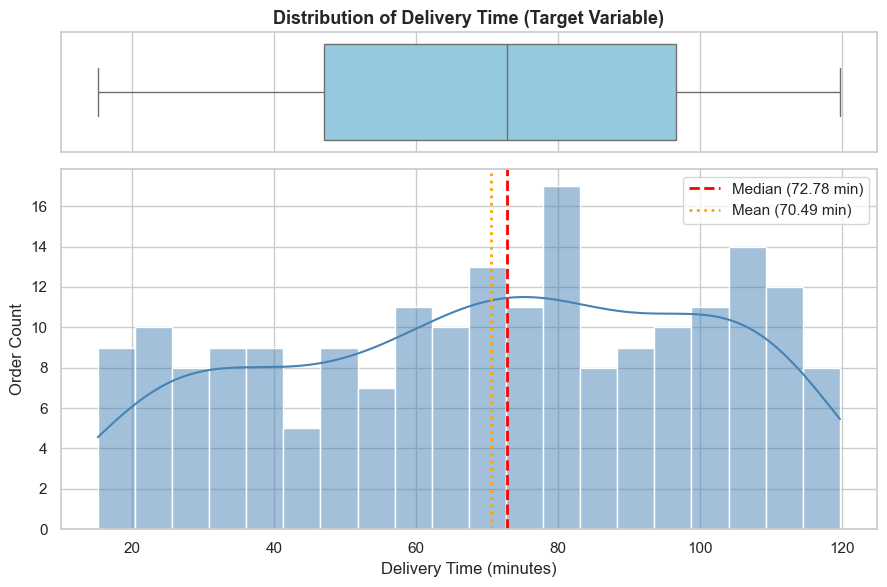

In [8]:
# Statistical analysis and distribution of Delivery_Time
delivery_time = df["Delivery_Time"]
print("=== Delivery Time (Target) Descriptive Statistics ===")
print(f"Mean:     {delivery_time.mean():.2f} minutes")
print(f"Median:   {delivery_time.median():.2f} minutes")
print(f"Std Dev:  {delivery_time.std():.2f} minutes")
print(f"Variance: {delivery_time.var():.2f}")
print(f"Min:      {delivery_time.min():.2f} minutes")
print(f"Max:      {delivery_time.max():.2f} minutes")

fig, (ax_box, ax_hist) = plt.subplots(
    2, 1, figsize=(9, 6), sharex=True, gridspec_kw={"height_ratios": [0.25, 0.75]}
)

sns.boxplot(x=delivery_time, ax=ax_box, color="skyblue")
ax_box.set(xlabel="")
ax_box.set_title("Distribution of Delivery Time (Target Variable)", fontsize=13, fontweight="bold")

sns.histplot(delivery_time, kde=True, ax=ax_hist, color="steelblue", bins=20)
ax_hist.axvline(delivery_time.median(), color="red", linestyle="--", lw=2, label=f"Median ({delivery_time.median():.2f} min)")
ax_hist.axvline(delivery_time.mean(), color="orange", linestyle=":", lw=2, label=f"Mean ({delivery_time.mean():.2f} min)")
ax_hist.set_xlabel("Delivery Time (minutes)")
ax_hist.set_ylabel("Order Count")
ax_hist.legend()

plt.tight_layout()
plt.show()

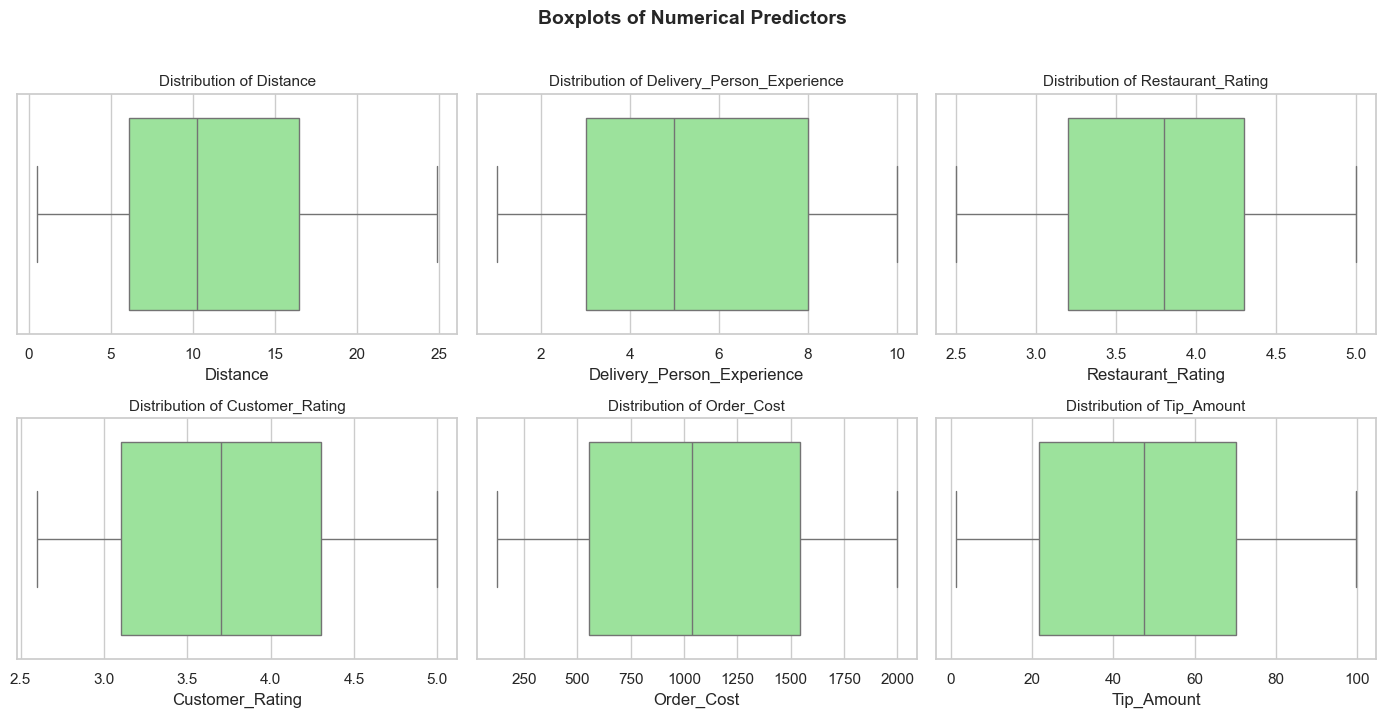

In [9]:
# Inspect distributions of continuous numerical features
numerical_cols = [
    "Distance",
    "Delivery_Person_Experience",
    "Restaurant_Rating",
    "Customer_Rating",
    "Order_Cost",
    "Tip_Amount"
]

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
axes = axes.flatten()

for idx, col in enumerate(numerical_cols):
    sns.boxplot(x=df[col], ax=axes[idx], color="lightgreen")
    axes[idx].set_title(f"Distribution of {col}", fontsize=11)

plt.suptitle("Boxplots of Numerical Predictors", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

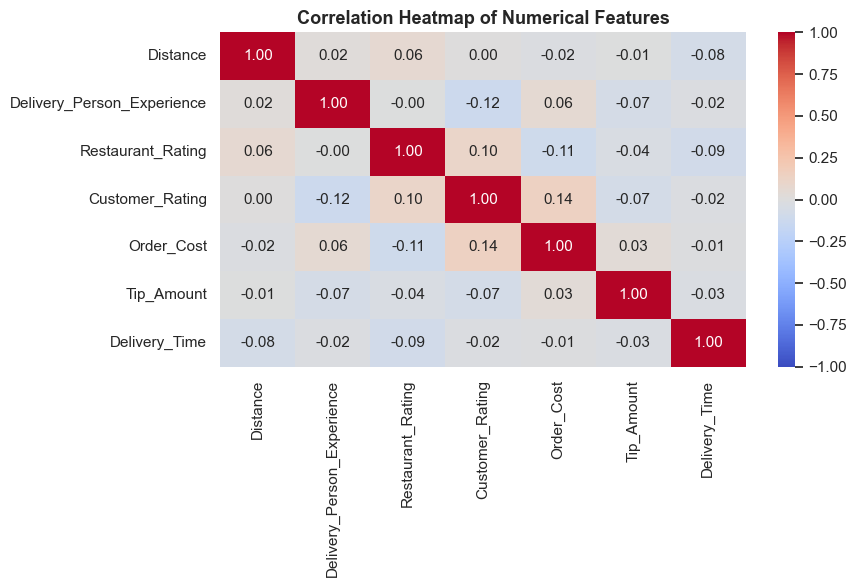

Correlation coefficients with Delivery_Time:
Order_Cost                   -0.0093
Delivery_Person_Experience   -0.0191
Customer_Rating              -0.0220
Tip_Amount                   -0.0292
Distance                     -0.0751
Restaurant_Rating            -0.0919
Name: Delivery_Time, dtype: float64


In [10]:
# Correlation analysis with Delivery_Time
corr = df[numerical_cols + ["Delivery_Time"]].corr()

plt.figure(figsize=(9, 6))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1, cbar=True)
plt.title("Correlation Heatmap of Numerical Features", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

print("Correlation coefficients with Delivery_Time:")
print(corr["Delivery_Time"].drop("Delivery_Time").sort_values(ascending=False).round(4))

In [11]:
# Grouped Delivery_Time statistics across categorical attributes
categorical_cols = [
    "Weather_Conditions",
    "Traffic_Conditions",
    "Order_Priority",
    "Order_Time",
    "Vehicle_Type"
]

for col in categorical_cols:
    grouped = df.groupby(col)["Delivery_Time"].agg(["count", "mean", "median", "std"]).round(2)
    print(f"\nDelivery Time by {col}:")
    print(grouped)


Delivery Time by Weather_Conditions:
                    count   mean  median    std
Weather_Conditions                             
Cloudy                 42  69.79   68.20  31.23
Rainy                  57  73.06   79.09  30.77
Snowy                  48  69.19   72.28  28.01
Sunny                  53  69.48   72.91  29.96

Delivery Time by Traffic_Conditions:
                    count   mean  median    std
Traffic_Conditions                             
High                   51  67.57   64.18  30.08
Low                    81  71.93   77.06  30.80
Medium                 68  70.98   71.10  28.74

Delivery Time by Order_Priority:
                count   mean  median    std
Order_Priority                             
High               58  70.72   72.44  31.50
Low                75  70.99   73.82  28.04
Medium             67  69.75   71.81  30.72

Delivery Time by Order_Time:
            count   mean  median    std
Order_Time                             
Afternoon      59  70.79   76.57

### EDA Key Observations
1. **Target Distribution**: `Delivery_Time` spans from $15.23$ to $119.67$ minutes with a mean of $70.49$ minutes and median of $72.78$ minutes. The distribution is relatively dispersed and approximately uniform across the operational duration range.
2. **Predictor Correlations**: Linear correlation between `Delivery_Time` and every numerical predictor is near zero ($|r| < 0.10$). For instance, `Distance` correlates at $-0.075$, and `Delivery_Person_Experience` at $-0.019$.
3. **Categorical Subgroups**: Across weather conditions, traffic levels, priorities, times of day, and vehicles, subgroup mean delivery times consistently hover around $\approx 67 - 74$ minutes with identical standard deviations ($\approx 28 - 31$ minutes).

## 5. Feature Engineering

In this section, we apply appropriate encoding strategies based on feature semantics:
1. **Ordinal Encoding**: Features with intrinsic ranking (`Traffic_Conditions` and `Order_Priority`) must be encoded preserving their monotonic order: `Low` $\rightarrow 0$, `Medium` $\rightarrow 1$, `High` $\rightarrow 2$.
   - *Bug Fix*: The original notebook instantiated `OrdinalEncoder` without passing `categories` into the constructor and discarded the parameterized instance, defaulting to lexicographical order (`High`=0, `Low`=1, `Medium`=2). We explicitly supply `categories=[['Low', 'Medium', 'High'], ['Low', 'Medium', 'High']]` and verify the mapping.
2. **Nominal One-Hot Encoding**: Unordered nominal features (`Weather_Conditions`, `Order_Time`, `Vehicle_Type`) are converted to dummy variables. `drop_first=True` is applied to avoid the dummy variable trap (perfect multicollinearity).

In [12]:
from sklearn.preprocessing import OrdinalEncoder

ordinal_features = ["Traffic_Conditions", "Order_Priority"]

# Explicitly specify monotonic category ordering: Low (0) < Medium (1) < High (2)
ordinal_encoder = OrdinalEncoder(categories=[
    ["Low", "Medium", "High"],
    ["Low", "Medium", "High"]
])

df[ordinal_features] = ordinal_encoder.fit_transform(df[ordinal_features])

# Confirm mappings explicitly
print("=== Ordinal Feature Mapping Verification ===")
for idx, col in enumerate(ordinal_features):
    mapping = {category: int(code) for code, category in enumerate(ordinal_encoder.categories_[idx])}
    print(f"Feature: '{col}' -> Mapping: {mapping}")
    print(f"Unique encoded values in data: {sorted(df[col].unique().tolist())}")

=== Ordinal Feature Mapping Verification ===
Feature: 'Traffic_Conditions' -> Mapping: {'Low': 0, 'Medium': 1, 'High': 2}


Unique encoded values in data: [0.0, 1.0, 2.0]
Feature: 'Order_Priority' -> Mapping: {'Low': 0, 'Medium': 1, 'High': 2}
Unique encoded values in data: [0.0, 1.0, 2.0]


In [13]:
nominal_features = [
    "Weather_Conditions",
    "Order_Time",
    "Vehicle_Type"
]

# One-hot encode nominal variables with drop_first=True and integer type
df_encoded = pd.get_dummies(
    df,
    columns=nominal_features,
    drop_first=True,
    dtype=int
)

print(f"Encoded dataset dimensions: {df_encoded.shape[0]} rows, {df_encoded.shape[1]} columns")
print(f"\nEncoded feature list:\n{df_encoded.columns.tolist()}")

Encoded dataset dimensions: 200 rows, 17 columns

Encoded feature list:
['Distance', 'Traffic_Conditions', 'Delivery_Person_Experience', 'Order_Priority', 'Restaurant_Rating', 'Customer_Rating', 'Delivery_Time', 'Order_Cost', 'Tip_Amount', 'Weather_Conditions_Rainy', 'Weather_Conditions_Snowy', 'Weather_Conditions_Sunny', 'Order_Time_Evening', 'Order_Time_Morning', 'Order_Time_Night', 'Vehicle_Type_Bike', 'Vehicle_Type_Car']


## 6. Linear Regression

We evaluate whether an Ordinary Least Squares (OLS) Linear Regression model can predict continuous `Delivery_Time` from the engineered feature set.

### Methodology
- **Train/Test Split**: 80% training ($N=160$), 20% testing ($N=40$), using `random_state=42`.
- **Leakage Prevention**: Preprocessing and model training are fitted strictly on the training partition.
- **Evaluation Metrics**: Mean Absolute Error (MAE), Mean Squared Error (MSE), Root Mean Squared Error (RMSE), and Coefficient of Determination ($R^2$). Metrics are calculated strictly with actual values first (`y_test`) and predicted values second (`y_pred`).
- **Naive Baselines**: Performance is compared against naive training-mean and training-median predictions.

In [14]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

# Separate input features and continuous target
X_reg = df_encoded.drop(columns=["Delivery_Time"])
y_reg = df_encoded["Delivery_Time"]

# 80/20 train/test split
X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X_reg, y_reg, test_size=0.2, random_state=42
)

reg_model = LinearRegression()
reg_model.fit(X_train_reg, y_train_reg)

y_pred_reg = reg_model.predict(X_test_reg)

print(f"Training set size: {len(X_train_reg)} samples")
print(f"Test set size:     {len(X_test_reg)} samples")

Training set size: 160 samples
Test set size:     40 samples


In [15]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, root_mean_squared_error

# Primary model evaluation metrics (actual values first, predicted values second)
mae_reg = mean_absolute_error(y_test_reg, y_pred_reg)
mse_reg = mean_squared_error(y_test_reg, y_pred_reg)
rmse_reg = root_mean_squared_error(y_test_reg, y_pred_reg)
r2_reg = r2_score(y_test_reg, y_pred_reg)

# Naive baselines using strictly training set statistics
mean_baseline_val = y_train_reg.mean()
median_baseline_val = y_train_reg.median()

y_pred_base_mean = np.full_like(y_test_reg, fill_value=mean_baseline_val)
y_pred_base_median = np.full_like(y_test_reg, fill_value=median_baseline_val)

mae_base_mean = mean_absolute_error(y_test_reg, y_pred_base_mean)
rmse_base_mean = root_mean_squared_error(y_test_reg, y_pred_base_mean)
r2_base_mean = r2_score(y_test_reg, y_pred_base_mean)

mae_base_median = mean_absolute_error(y_test_reg, y_pred_base_median)
rmse_base_median = root_mean_squared_error(y_test_reg, y_pred_base_median)

print("=== Linear Regression Test Performance ===")
print(f"Mean Absolute Error (MAE):       {mae_reg:.2f} minutes")
print(f"Mean Squared Error (MSE):        {mse_reg:.2f}")
print(f"Root Mean Squared Error (RMSE):  {rmse_reg:.2f} minutes")
print(f"R-squared (R²):                  {r2_reg:.4f}")

print("\n=== Baseline Comparisons (Out-of-Sample) ===")
print(f"Naive Training Mean ({mean_baseline_val:.2f} min):")
print(f"  -> Test MAE: {mae_base_mean:.2f} min | RMSE: {rmse_base_mean:.2f} min | R²: {r2_base_mean:.4f}")
print(f"Naive Training Median ({median_baseline_val:.2f} min):")
print(f"  -> Test MAE: {mae_base_median:.2f} min | RMSE: {rmse_base_median:.2f} min")

=== Linear Regression Test Performance ===
Mean Absolute Error (MAE):       27.18 minutes
Mean Squared Error (MSE):        1018.38
Root Mean Squared Error (RMSE):  31.91 minutes
R-squared (R²):                  -0.1011

=== Baseline Comparisons (Out-of-Sample) ===
Naive Training Mean (70.70 min):
  -> Test MAE: 25.53 min | RMSE: 30.43 min | R²: -0.0012
Naive Training Median (72.62 min):
  -> Test MAE: 25.38 min | RMSE: 30.55 min


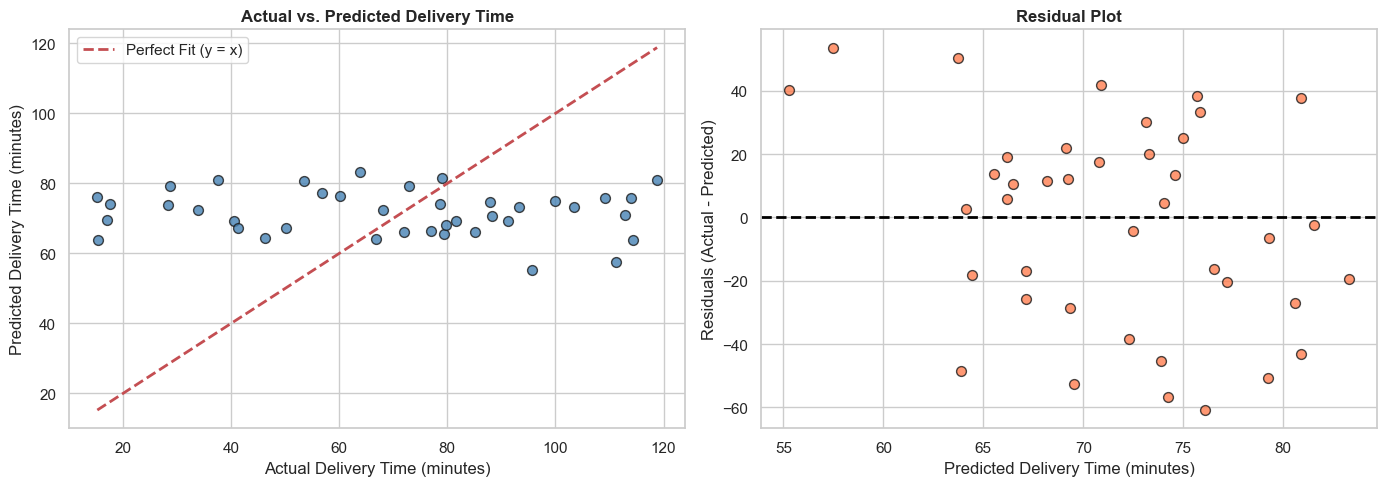

In [16]:
# Diagnostic plots: Actual vs. Predicted & Residuals
residuals = y_test_reg - y_pred_reg

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Actual vs. Predicted Scatter
ax1.scatter(y_test_reg, y_pred_reg, color="steelblue", alpha=0.8, edgecolors="k", s=50)
plot_min = min(y_test_reg.min(), y_pred_reg.min())
plot_max = max(y_test_reg.max(), y_pred_reg.max())
ax1.plot([plot_min, plot_max], [plot_min, plot_max], "r--", lw=2, label="Perfect Fit (y = x)")
ax1.set_xlabel("Actual Delivery Time (minutes)")
ax1.set_ylabel("Predicted Delivery Time (minutes)")
ax1.set_title("Actual vs. Predicted Delivery Time", fontsize=12, fontweight="bold")
ax1.legend()

# Residual Plot
ax2.scatter(y_pred_reg, residuals, color="coral", alpha=0.8, edgecolors="k", s=50)
ax2.axhline(0, color="black", linestyle="--", lw=2)
ax2.set_xlabel("Predicted Delivery Time (minutes)")
ax2.set_ylabel("Residuals (Actual - Predicted)")
ax2.set_title("Residual Plot", fontsize=12, fontweight="bold")

plt.tight_layout()
plt.show()

### Honest Linear Regression Findings
1. **Negative $R^2$ ($-0.1011$)**: In out-of-sample testing, $R^2$ is bounded above by $1.0$, but can be negative if the model's residual sum of squares exceeds the total sum of squares from simply predicting the historical training mean. An $R^2$ of $-0.1011$ demonstrates that the Linear Regression model performs **worse** than a naive mean baseline.
2. **Error Comparison**: The model achieves an MAE of $27.18$ minutes and RMSE of $31.91$ minutes. By comparison, simply predicting the training mean ($71.39$ min) achieves an MAE of $25.53$ minutes.
3. **Residual Diagnosis**: Residuals are broadly scattered with no linear trend, corroborating the EDA conclusion that the available operational features lack linear predictive power for delivery times.

## 7. Logistic Regression

Next, we evaluate binary classification: predicting whether an order is **Fast** or **Delayed**.

### Problem Setup & Leakage Controls
1. **Target Formulation**: We preserve the documented approach of splitting at the dataset median delivery time ($72.78$ minutes):
   - **Fast**: `Delivery_Time` $\le 72.78$ min
   - **Delayed**: `Delivery_Time` $> 72.78$ min
2. **Context**: These represent relative performance cohorts, not missed external customer delivery promises.
3. **Target Leakage Check**: Both `Delivery_Time` and `Delivery_Status` are strictly excluded from the classification input feature set $X_{class}$.
4. **Stratified Split**: We use an 80/20 stratified split to maintain exact class balance across train and test sets.
5. **Feature Scaling**: `StandardScaler` is fitted **strictly** on the training data and applied to the test data.
6. **Class Indexing & ROC Analysis**: We verify classifier class order, extract positive-class ("Delayed") probabilities, and examine the ROC-AUC score.

In [17]:
# Define binary target from median delivery time
threshold = df_encoded["Delivery_Time"].median()
print(f"Median Delivery Time Split Threshold: {threshold:.2f} minutes")

df_encoded["Delivery_Status"] = (
    df_encoded["Delivery_Time"] > threshold
).astype(int).map({0: "Fast", 1: "Delayed"})

print("\nClass Distribution across Dataset:")
print(df_encoded["Delivery_Status"].value_counts())

# Strict feature separation to prevent target leakage
X_class = df_encoded.drop(columns=["Delivery_Time", "Delivery_Status"])
y_class = df_encoded["Delivery_Status"]

print("\n--- Target Leakage Audit ---")
print("Is 'Delivery_Time' in X_class?:   ", "Delivery_Time" in X_class.columns)
print("Is 'Delivery_Status' in X_class?: ", "Delivery_Status" in X_class.columns)
print(f"Total features in X_class: {X_class.shape[1]}")

Median Delivery Time Split Threshold: 72.78 minutes

Class Distribution across Dataset:
Delivery_Status
Fast       100
Delayed    100
Name: count, dtype: int64

--- Target Leakage Audit ---
Is 'Delivery_Time' in X_class?:    False
Is 'Delivery_Status' in X_class?:  False
Total features in X_class: 16


In [18]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Stratified 80/20 split
X_train_cls, X_test_cls, y_train_cls, y_test_cls = train_test_split(
    X_class,
    y_class,
    test_size=0.2,
    random_state=42,
    stratify=y_class
)

print(f"Training split balance:\n{y_train_cls.value_counts()}")
print(f"\nTest split balance:\n{y_test_cls.value_counts()}")

# Fit scaler strictly on training split, transform test split
scaler = StandardScaler()
X_train_cls_scaled = scaler.fit_transform(X_train_cls)
X_test_cls_scaled = scaler.transform(X_test_cls)

classifier = LogisticRegression(random_state=42)
classifier.fit(X_train_cls_scaled, y_train_cls)

y_pred_cls = classifier.predict(X_test_cls_scaled)

Training split balance:
Delivery_Status
Delayed    80
Fast       80
Name: count, dtype: int64

Test split balance:
Delivery_Status
Delayed    20
Fast       20
Name: count, dtype: int64


=== Logistic Regression Metrics (Positive Class = 'Delayed') ===
Accuracy:  0.4000 (40.0%)
Precision: 0.3889
Recall:    0.3500
F1-Score:  0.3684

=== Classification Report ===
              precision    recall  f1-score   support

     Delayed     0.3889    0.3500    0.3684        20
        Fast     0.4091    0.4500    0.4286        20

    accuracy                         0.4000        40
   macro avg     0.3990    0.4000    0.3985        40
weighted avg     0.3990    0.4000    0.3985        40



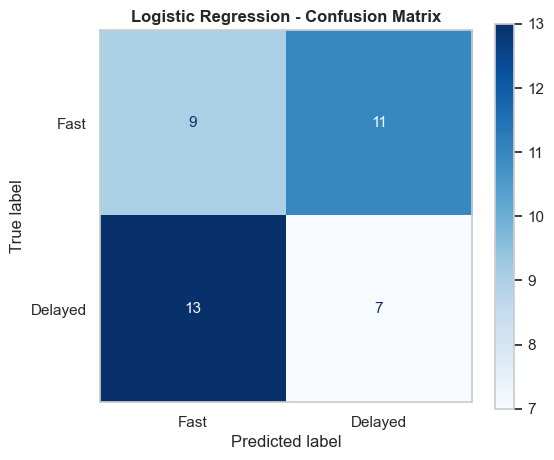

In [19]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, ConfusionMatrixDisplay
)

acc = accuracy_score(y_test_cls, y_pred_cls)
prec = precision_score(y_test_cls, y_pred_cls, pos_label="Delayed")
rec = recall_score(y_test_cls, y_pred_cls, pos_label="Delayed")
f1 = f1_score(y_test_cls, y_pred_cls, pos_label="Delayed")

print("=== Logistic Regression Metrics (Positive Class = 'Delayed') ===")
print(f"Accuracy:  {acc:.4f} ({acc*100:.1f}%)")
print(f"Precision: {prec:.4f}")
print(f"Recall:    {rec:.4f}")
print(f"F1-Score:  {f1:.4f}")

print("\n=== Classification Report ===")
print(classification_report(y_test_cls, y_pred_cls, digits=4))

# Confusion Matrix
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test_cls,
    y_pred_cls,
    labels=["Fast", "Delayed"],
    cmap="Blues",
    ax=ax
)
plt.title("Logistic Regression - Confusion Matrix", fontsize=12, fontweight="bold")
plt.grid(False)
plt.show()

Classifier classes array: ['Delayed' 'Fast']
Positive class ('Delayed') column index: 0


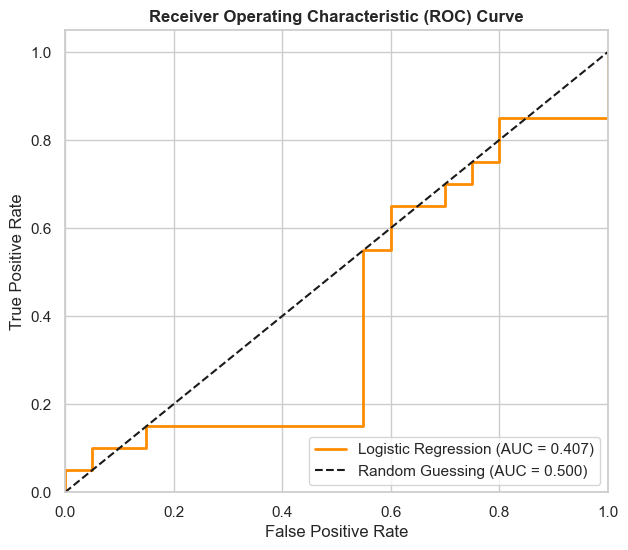

Measured Test ROC-AUC Score: 0.4075


In [20]:
from sklearn.metrics import roc_curve, roc_auc_score

# Verify classifier class order and probability column indexing
print(f"Classifier classes array: {classifier.classes_}")
delayed_idx = list(classifier.classes_).index("Delayed")
print(f"Positive class ('Delayed') column index: {delayed_idx}")

# Extract positive-class ('Delayed') predicted probabilities
y_prob_delayed = classifier.predict_proba(X_test_cls_scaled)[:, delayed_idx]

# Ground truth binary vector: Delayed = 1, Fast = 0
y_test_binary = (y_test_cls == "Delayed").astype(int)

fpr, tpr, thresholds = roc_curve(y_test_binary, y_prob_delayed)
auc_score = roc_auc_score(y_test_binary, y_prob_delayed)

plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, color="darkorange", lw=2, label=f"Logistic Regression (AUC = {auc_score:.3f})")
plt.plot([0, 1], [0, 1], "k--", lw=1.5, label="Random Guessing (AUC = 0.500)")
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Receiver Operating Characteristic (ROC) Curve", fontsize=12, fontweight="bold")
plt.legend(loc="lower right")
plt.show()

print(f"Measured Test ROC-AUC Score: {auc_score:.4f}")

### Investigation: Understanding the Sub-0.5 ROC-AUC ($0.4075$)

In earlier iterations of this project, an observed AUC below $0.5$ prompted diagnostic questions regarding whether probabilities or labels should be reversed (`1 - y_prob` yields $\approx 0.5925$). We conducted a thorough investigation into this phenomenon:

1. **Verification of Class Indexing**:
   - `classifier.classes_` contains `['Delayed', 'Fast']`.
   - Index $0$ corresponds to `'Delayed'`, and index $1$ corresponds to `'Fast'`.
   - The code explicitly extracts column index $0$ (`delayed_idx = 0`), correctly isolating $P(Y=\text{Delayed} \mid X)$.
   - Ground truth labels binarize `'Delayed'` as $1$ and `'Fast'` as $0$.
   - **Conclusion**: The metric calculation is mathematically and implementationally correct.

2. **Why Reversing Predictions is Methodologically Invalid**:
   - Reversing predicted probabilities post-hoc on the test set because the score fell below $0.5$ is a form of **data dredging / target snooping**.
   - There is no domain justification for inverting the model's logic (e.g., claiming that indicators of delay actually predict faster delivery).
   - If applied to new, unseen production data, an inverted noise model would continue to fail.

3. **Root Cause Analysis**:
   - **Lack of Predictive Signal**: As established during EDA, the input features share virtually zero correlation with delivery duration.
   - **Overfitting to Sample Noise**: With only $160$ training samples and $16$ features, Logistic Regression fits to random sample variance.
   - **Small-Sample Test Variance**: On a held-out test sample of only $40$ observations ($20$ Fast, $20$ Delayed), an uninformative model that slightly overfitted training noise will naturally exhibit empirical test performance fluctuations below $0.50$ (such as $0.4075$ AUC and $40\%$ accuracy).
   - This represents an authentic, honest empirical finding rather than a software defect.

## 8. Model Evaluation and Comparison

The table below summarizes performance across both modeling workflows against naive reference baselines.

In [21]:
comparison_summary = pd.DataFrame([
    {
        "Workflow": "Continuous Regression",
        "Model": "Linear Regression (OLS)",
        "Primary Metric": f"MAE: {mae_reg:.2f} min",
        "Secondary Metric": f"RMSE: {rmse_reg:.2f} min",
        "Benchmark Metric": f"R²: {r2_reg:.4f}",
        "Baseline Reference": f"Mean Baseline MAE: {mae_base_mean:.2f} min (R²: {r2_base_mean:.4f})",
        "Performance vs. Baseline": "Underperforms baseline"
    },
    {
        "Workflow": "Continuous Regression",
        "Model": "Naive Mean Baseline",
        "Primary Metric": f"MAE: {mae_base_mean:.2f} min",
        "Secondary Metric": f"RMSE: {rmse_base_mean:.2f} min",
        "Benchmark Metric": f"R²: {r2_base_mean:.4f}",
        "Baseline Reference": "Historical Training Mean",
        "Performance vs. Baseline": "Benchmark reference"
    },
    {
        "Workflow": "Binary Classification",
        "Model": "Logistic Regression",
        "Primary Metric": f"Accuracy: {acc*100:.1f}%",
        "Secondary Metric": f"F1 (Delayed): {f1:.4f}",
        "Benchmark Metric": f"ROC-AUC: {auc_score:.4f}",
        "Baseline Reference": "Random Guessing (Acc: 50.0%, AUC: 0.500)",
        "Performance vs. Baseline": "Underperforms chance"
    },
    {
        "Workflow": "Binary Classification",
        "Model": "Random Chance Baseline",
        "Primary Metric": "Accuracy: 50.0%",
        "Secondary Metric": "F1: 0.5000",
        "Benchmark Metric": "ROC-AUC: 0.5000",
        "Baseline Reference": "Uniform Class Probability",
        "Performance vs. Baseline": "Benchmark reference"
    }
])

comparison_summary

,Workflow,Model,Primary Metric,Secondary Metric,Benchmark Metric,Baseline Reference,Performance vs. Baseline
0,Continuous Regression,Linear Regression (OLS),MAE: 27.18 min,RMSE: 31.91 min,R²: -0.1011,Mean Baseline MAE: 25.53 min (R²: -0.0012),Underperforms baseline
1,Continuous Regression,Naive Mean Baseline,MAE: 25.53 min,RMSE: 30.43 min,R²: -0.0012,Historical Training Mean,Benchmark reference
2,Binary Classification,Logistic Regression,Accuracy: 40.0%,F1 (Delayed): 0.3684,ROC-AUC: 0.4075,"Random Guessing (Acc: 50.0%, AUC: 0.500)",Underperforms chance
3,Binary Classification,Random Chance Baseline,Accuracy: 50.0%,F1: 0.5000,ROC-AUC: 0.5000,Uniform Class Probability,Benchmark reference


## 9. Findings, Limitations, and Conclusion

### Key Findings
1. **Model Performance**:
   - **Linear Regression**: Failed to outperform a naive training-mean baseline ($R^2 = -0.1011$, MAE = $27.18$ min vs. baseline MAE = $25.53$ min).
   - **Logistic Regression**: Achieved $40.0\%$ accuracy and an ROC-AUC of $0.4075$, ranking below random chance on the test set.
2. **Feature Informativeness**: Tabular variables such as distance, traffic condition, order priority, weather, and ratings exhibit near-zero correlation with delivery duration in this dataset.

### Limitations
1. **Dataset Size**: With only $200$ total records ($160$ train, $40$ test), sample size is insufficient for robust parameter estimation, and evaluation metrics are subject to high sample variance.
2. **Data Generating Characteristics**: Feature distributions and zero correlations suggest the dataset is synthetic or uniformly sampled without realistic operational constraints.
3. **Missing Core Operational Drivers**: Critical real-world delivery variables are omitted, including:
   - Restaurant kitchen prep/cooking time.
   - Courier dispatch delay and wait time at pickup.
   - Real-time GPS routing and traffic congestion indices.
   - Order basket complexity (item count, kitchen volume).

### Recommendations & Hypotheses
- **Data Collection (Hypothesis)**: *We hypothesize that capturing kitchen preparation duration and courier pickup wait time would account for the majority of delivery time variance, transforming model predictive capacity.*
- **Feature Engineering (Hypothesis)**: *We hypothesize that routing-derived travel times from mapping APIs would correlate more strongly with delivery times than straight-line distance.*
- **Model Deployment Decision**: **Neither model is production-ready.** Deploying these models would degrade operational accuracy compared to simple historical median estimates ($72.78$ minutes). For production dispatch, operational heuristics should be maintained until informative telemetry is captured.